# 04 — Does radiation change where the killers sit relative to the tumor?

The effector arm is only readable spatially (`00`: 513 CD8 T cells in single cell, 45,824 in
spatial). This notebook asks the question the RT-helps-CAR-T argument most directly predicts:

> **With RT added to Cy + CAR-T, do CD8 T and NK cells get *into* the tumor, rather than
> sitting at its edge — and does that also happen in the tumor that was never irradiated?**

### Why this is geometry and not abundance
Per-tissue fractions are unusable here: CD8_T swings 51x between sections because sections
caught different amounts of tumor vs stroma (`00 §5`). Every metric below is **internally
normalized** — an effector population is compared to *a random annotated non-tumor cell of the
same section* — so how much tumor a section happened to catch cancels out.

| metric | definition (per tissue, per effector type E) | reads as |
|---|---|---|
| `prox_<r>` | log2( mean tumor fraction among neighbors within r µm of E cells / same for reference cells ) | > 0: E sits in more tumor-rich surroundings than a random non-tumor cell |
| `core` | log2( share of E in tumor core / share of reference cells in core ), core = >= `CORE_FRAC` (20%) tumor within 50 µm | > 0: E penetrates the tumor bed |
| `ntd` | log2( median distance from E to nearest tumor cell / same for reference ) | < 0: E is closer to tumor than a random non-tumor cell |
| `cd8_treg_iface` | log2(CD8:Treg within `IFACE_UM` of tumor) − log2(CD8:Treg tissue-wide) | > 0: the tumor interface is effector-skewed |
| `prox30_vs_B` | log2( mean tumor fraction within 30 µm of E / same for B cells ) | the **lymphoid-matched** control: > 0 means E is more tumor-associated than another lymphocyte |

`core` uses a **20%** tumor threshold, not 50%: treated sections are only 4-6% tumor, and at 50%
fewer than 30 reference cells sit in "core" in 14 of 24 treated sections (checked while writing
this notebook). It is only defined where at least `CORE_MIN_REF` reference cells sit in core; in a
section with a tiny tumor bed the ratio is a ratio of two near-zero counts and swings by ±10 log2.

`prox_<r>` at several radii is a curve, which ties this notebook to the one RT effect that
survived in `spp1Analysis` — a change in spatial **range** (`08 §C`).

### Distances are in true microns
`obsm['spatial']` is full-resolution pixels, and 0.34 µm is one full-resolution pixel. The
`px × hires_scale × 0.34` convention used in `spp1Analysis` 02-08 under-states distance 4.2-5x and
varies by slide. Here **µm = px × 0.34, no hires scale**, and §2 checks it against cell spacing
(nearest-neighbor distance should be ~7-10 µm).

### Design rules (same as `01`-`03`)
* RT contrasts are site-matched and run per CAR background; sign agreement earns a main effect,
  the PSCA-minus-TAG72 interaction is printed beside it (`02b`).
* Tissues, not cells, are the unit. `RTCyPSCA_1_2` and `RTCyPSCA_1_5` are two sections of one
  mouse (`mouse` column `RTCyPSCA_1_2_1`/`_2`), so they are averaged into one animal before any
  contrast.
* Null distributions are **exact relabelings** inside each background x site stratum.
* `NoTx` is a pipeline check only. The CAR axis (PSCA vs TAG72) is the realistic yardstick.

Spatial Tu1/Tu2 pairing by replicate number is not verified for this object, so the
within-mouse difference-in-differences of `01`/`03` is replaced by a **between-tissue
site x RT interaction** (§7).

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re, itertools, time
from pathlib import Path
import numpy as np, pandas as pd, anndata as ad, zarr
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy import stats

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 400)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T")
_LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _HPC if _HPC.exists() else _LOC
ZARR_FILE = (PROJ/"data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC" if PROJ is _HPC
             else PROJ/"data/zarrFiles/1_C2l_annotations_400")
OUT = PROJ/"results/rt_advantage"; FIG = OUT/"figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

CART_PAIRS = [("PSCA", "RTCyPSCA", "CyPSCA"), ("TAG72", "RTCyT72", "CyT72")]
SITE = {1: "irradiated", 2: "abscopal"}
ARM_ORDER = ["NoTx", "CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
COL = {"NoTx": "#9e9e9e", "CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1",
       "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}

MICRONS_PER_PIXEL = 0.34          # one FULL-RES pixel; no hires scale (see the markdown above)
TUMOR    = "Cancer_cell"
EFFECTORS = ["CD8_T", "NK", "NKT", "CD4_T", "Treg", "B", "M1_like_Mac", "M2_like_Mac"]
NOT_REF   = {TUMOR, "Unknown", "Erythrocyte"}   # reference = annotated non-tumor cells
RADII     = [15, 30, 50, 100, 200]               # µm
CORE_R, CORE_FRAC = 50, 0.2                      # core = >= 20% tumor within 50 µm (see below)
CORE_FRAC_SENS    = [0.1, 0.3]
CORE_MIN_REF      = 200                          # below this many reference cells in core, `core` = NaN
IFACE_UM  = 30                                   # "at the tumor interface" = within 30 µm
MIN_TUMOR, MIN_EFF = 300, 50                    # per-tissue usability floors
HEADLINE  = ["CD8_T|prox_30", "CD8_T|prox30_vs_B", "CD8_T|core", "CD8_T|ntd", "NK|prox_30",
             "NK|prox30_vs_B", "CD8_T|cd8_treg_iface"]
SEED = 0
print(f"PROJ = {PROJ}\nZARR = {ZARR_FILE}")

PROJ = /Users/janzules/Roselab/Spatial/CAR_T
ZARR = /Users/janzules/Roselab/Spatial/CAR_T/data/zarrFiles/1_C2l_annotations_400


## 2. Load obs + coordinates only, and check the micron scale

No expression is needed, so only `obs` and `obsm/spatial` are read from the zarr store — a few
seconds instead of loading the 2M x 19k matrix.

In [2]:
t0 = time.time()
g = zarr.open_group(str(ZARR_FILE/"tables/segmentation_counts"), mode="r")
so = ad.io.read_elem(g["obs"])[["tissue", "condition", "tumor_loc", "mouse",
                                "c2l_consolidated", "c2l_strict"]].copy()
XY = np.asarray(g["obsm"]["spatial"][:], float) * MICRONS_PER_PIXEL
for c in ["tissue", "condition", "mouse", "c2l_consolidated", "c2l_strict"]:
    so[c] = so[c].astype(str)
so["site"] = so["tumor_loc"].astype(int)
print(f"{len(so):,} cells read in {time.time()-t0:.0f}s")

# tissue -> animal. Two sections of one mouse carry a 4-part mouse id (RTCyPSCA_1_2_1 / _2).
tis = so.groupby("tissue", observed=True).agg(arm=("condition", "first"), site=("site", "first"),
                                              mouse=("mouse", "first"), n_cells=("site", "size"))
tis["animal"] = [m.group(1) if (m := re.match(r"^(.+_\d+_\d+)_\d+$", mo)) else t
                 for t, mo in zip(tis.index, tis.mouse)]
tis["RT"] = tis.arm.str.startswith("RT")
tis["cart"] = tis.arm.map({"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72",
                           "RTCyT72": "TAG72", "NoTx": "none"})
merged = tis.groupby("animal").filter(lambda d: len(d) > 1)
print(f"\nsections merged into one animal: {merged.groupby('animal').apply(lambda d: list(d.index)).to_dict()}")

# micron check: median nearest-neighbor distance between cells, per tissue
rng = np.random.default_rng(SEED)
nn_rows = []
for t, idx in so.groupby("tissue", observed=True).indices.items():
    xy = XY[idx]
    q = xy[rng.choice(len(xy), min(20000, len(xy)), replace=False)]
    d, _ = cKDTree(xy).query(q, k=2)
    nn_rows.append(dict(tissue=t, median_nn_um=float(np.median(d[:, 1]))))
nn = pd.DataFrame(nn_rows).set_index("tissue")
tis = tis.join(nn)
print(f"\nmedian nearest-neighbor distance across tissues: {nn.median_nn_um.min():.1f} - "
      f"{nn.median_nn_um.max():.1f} µm (median {nn.median_nn_um.median():.1f})")
assert nn.median_nn_um.between(4, 20).all(), "cell spacing is not cell-sized — the µm scale is wrong"
print("-> cell-sized spacing: px x 0.34 is microns.")

2,088,557 cells read in 5s

sections merged into one animal: {'RTCyPSCA_1_2': ['RTCyPSCA_1_2', 'RTCyPSCA_1_5']}



median nearest-neighbor distance across tissues: 6.6 - 9.8 µm (median 8.0)
-> cell-sized spacing: px x 0.34 is microns.


## 3. Per-tissue geometry

For every annotated non-tumor cell (the effectors are a subset of these): the distance to the
nearest tumor cell, and the tumor fraction among all cells within each radius (unlabeled
`Unknown` cells count in the denominator — they occupy space — but are never a reference cell).

In [3]:
def tissue_geometry(xy, lab, radii=RADII):
    """Per-cell geometry for the focal (annotated non-tumor) cells of one tissue."""
    is_t = lab == TUMOR
    focal = np.where(~np.isin(lab, list(NOT_REF)))[0]
    tree_all, tree_t = cKDTree(xy), cKDTree(xy[is_t])
    d_t, _ = tree_t.query(xy[focal], k=1, workers=-1)
    out = {"idx": focal, "lab": lab[focal], "d_tum": d_t}
    for r in sorted(set(radii) | {CORE_R}):
        n_all = tree_all.query_ball_point(xy[focal], r, return_length=True, workers=-1) - 1
        n_t = tree_t.query_ball_point(xy[focal], r, return_length=True, workers=-1)
        out[f"tf_{r}"] = n_t / np.maximum(n_all, 1)
    return out


def tissue_metrics(geo, lab_all, core_frac=CORE_FRAC, radii=RADII):
    """One row per effector: the internally-normalized metrics of the markdown table."""
    lab = geo["lab"]
    ref = np.ones(len(lab), bool)               # every focal cell is a reference cell
    n_t = int((lab_all == TUMOR).sum())
    core = geo[f"tf_{CORE_R}"] >= core_frac
    iface = geo["d_tum"] <= IFACE_UM
    rows = []
    for e in EFFECTORS:
        m = lab == e
        r = dict(effector=e, n_eff=int(m.sum()), n_tumor=n_t,
                 usable=bool(m.sum() >= MIN_EFF and n_t >= MIN_TUMOR),
                 ntd_um=float(np.median(geo["d_tum"][m])) if m.any() else np.nan)
        if m.sum() >= 5:
            for rad in radii:
                r[f"prox_{rad}"] = np.log2((geo[f"tf_{rad}"][m].mean() + 1e-4)
                                           / (geo[f"tf_{rad}"][ref].mean() + 1e-4))
            r["core"] = (np.log2(((core & m).sum() + 0.5) / (m.sum() + 1)
                                 / (((core & ref).sum() + 0.5) / (ref.sum() + 1)))
                         if (core & ref).sum() >= CORE_MIN_REF else np.nan)
            r["ntd"] = np.log2((np.median(geo["d_tum"][m]) + 1) / (np.median(geo["d_tum"][ref]) + 1))
        rows.append(r)
    # lymphoid-matched control: E against B cells of the same section, not against all cells
    b = lab == "B"
    for r in rows:
        m = lab == r["effector"]
        if r["effector"] in ("CD8_T", "NK", "NKT", "CD4_T", "Treg") and m.sum() >= 5 and b.sum() >= MIN_EFF:
            r["prox30_vs_B"] = np.log2((geo["tf_30"][m].mean() + 1e-4) / (geo["tf_30"][b].mean() + 1e-4))
    # effector:suppressor balance at the tumor interface, against the tissue-wide balance
    c8, tr = lab == "CD8_T", lab == "Treg"
    iface_bal = (np.log2(((c8 & iface).sum() + 0.5) / ((tr & iface).sum() + 0.5))
                 - np.log2((c8.sum() + 0.5) / (tr.sum() + 0.5)))
    for r in rows:
        if r["effector"] == "CD8_T":
            r["cd8_treg_iface"] = iface_bal
            r["usable_treg"] = bool(tr.sum() >= 20 and c8.sum() >= MIN_EFF)
    return rows


rows, rows_sens, rows_strict = [], [], []
GEO = {}
t0 = time.time()
for i, (t, idx) in enumerate(so.groupby("tissue", observed=True).indices.items(), 1):
    lab = so["c2l_consolidated"].values[idx]
    geo = tissue_geometry(XY[idx], lab)
    GEO[t] = dict(idx=idx[geo["idx"]], lab=geo["lab"], d_tum=geo["d_tum"],
                  tf=geo[f"tf_{CORE_R}"])
    rows += [dict(tissue=t, **r) for r in tissue_metrics(geo, lab)]
    for cf in CORE_FRAC_SENS:
        rows_sens += [dict(tissue=t, core_frac=cf, effector=r["effector"], core=r.get("core"))
                      for r in tissue_metrics(geo, lab, core_frac=cf)]
    lab_s = so["c2l_strict"].values[idx]                         # label-sensitivity pass
    geo_s = tissue_geometry(XY[idx], lab_s, radii=[30])
    rows_strict += [dict(tissue=t, effector=r["effector"], n_eff=r["n_eff"],
                         prox_30=r.get("prox_30"), core=r.get("core"), ntd=r.get("ntd"))
                    for r in tissue_metrics(geo_s, lab_s, radii=[30]) if r["effector"] in ("CD8_T", "NK")]
    print(f"[{i:2d}/32] {t:<14s} {len(idx):>7,} cells  {(lab == TUMOR).sum():>6,} tumor  "
          f"{(lab == 'CD8_T').sum():>5,} CD8  {time.time()-t0:5.0f}s", flush=True)

M = pd.DataFrame(rows).merge(tis[["arm", "site", "animal", "RT", "cart"]], left_on="tissue",
                             right_index=True)
M.to_csv(OUT/"infiltration_metrics_per_tissue.csv", index=False)

[ 1/32] CyPSCA_1_1     108,895 cells   9,022 tumor  5,347 CD8      0s


[ 2/32] CyPSCA_1_2      55,540 cells  12,378 tumor  1,483 CD8      0s


[ 3/32] CyPSCA_1_3      33,085 cells     634 tumor    248 CD8      1s


[ 4/32] CyPSCA_1_4      27,025 cells   1,276 tumor    847 CD8      1s


[ 5/32] CyPSCA_2_1      86,108 cells     375 tumor    435 CD8      1s


[ 6/32] CyPSCA_2_2      61,384 cells     477 tumor     94 CD8      1s


... (22 outputs left out)

[29/32] RTCyT72_1_4     65,460 cells   3,350 tumor     31 CD8      4s


[30/32] RTCyT72_2_1     76,611 cells   1,540 tumor    643 CD8      5s


[31/32] RTCyT72_2_2     71,223 cells     541 tumor     72 CD8      5s


[32/32] RTCyT72_2_4    104,380 cells   7,933 tumor  1,186 CD8      5s


## 4. What each tissue looks like, and which tissues can carry each metric

In [4]:
MET = [f"prox_{r}" for r in RADII] + ["core", "ntd", "prox30_vs_B", "cd8_treg_iface"]
cd8 = M[M.effector == "CD8_T"].set_index("tissue")
show = cd8[["arm", "site", "animal", "n_tumor", "n_eff", "usable", "ntd_um", "prox_30",
            "core", "ntd", "cd8_treg_iface"]].join(tis[["median_nn_um"]])
print("CD8_T, per tissue (n_eff = CD8 cells; ntd_um = median CD8-to-nearest-tumor distance)")
print(show.sort_values(["arm", "site"]).round(2).to_string())

print("\nusable tissues (>= {MIN_TUMOR} tumor cells and >= {MIN_EFF} effector cells), by arm x site:")
u = M[M.usable].groupby(["effector", "arm", "site"]).tissue.count().unstack(["arm", "site"]).fillna(0)
print(u.astype(int).to_string())

print("\nface validity — median metric over usable treated tissues, per effector:")
print(M[M.usable & (M.arm != "NoTx")].groupby("effector")[["prox_15", "prox_30", "prox_100",
                                                            "core", "ntd", "ntd_um"]]
        .median().round(2).to_string())
print("""
  READ: every annotated LYMPHOID label (B, Treg, CD4, NKT, CD8) sits in more tumor-rich
  surroundings than a random annotated non-tumor cell, B and Treg most of all — and this holds
  under c2l_strict labels too. The reference is ~60% neutrophils, which fill necrotic / stromal
  space. So "CD8 is tumor-proximal" is NOT by itself evidence of cytotoxic infiltration; it is
  shared by every lymphocyte label. The `prox30_vs_B` column asks the effector-specific question.""")
print("reference-cell composition (% of annotated non-tumor cells):")
_ref = so.loc[~so.c2l_consolidated.isin(NOT_REF), "c2l_consolidated"]
print((_ref.value_counts(normalize=True).head(6)*100).round(1).to_string())

# animal-level table, the unit every contrast below runs on
def to_wide(M_):
    m = M_.copy()
    for c in MET:
        if c in m: m.loc[~m.usable, c] = np.nan
    if "usable_treg" in m:
        m.loc[(m.effector == "CD8_T") & ~m.usable_treg.fillna(False).astype(bool), "cd8_treg_iface"] = np.nan
    long = m.melt(id_vars=["animal", "effector"], value_vars=[c for c in MET if c in m],
                  var_name="metric").dropna()
    long["col"] = long.effector + "|" + long.metric
    long = long[~((long.metric == "cd8_treg_iface") & (long.effector != "CD8_T"))]
    return long.pivot_table(index="animal", columns="col", values="value", aggfunc="mean")


W = to_wide(M)
AM_ALL = tis.groupby("animal").agg(arm=("arm", "first"), site=("site", "first"),
                                   RT=("RT", "first"), cart=("cart", "first"))
AM = AM_ALL.loc[W.index]
print(f"\nanimal-level table: {W.shape[0]} animals x {W.shape[1]} effector|metric columns")

CD8_T, per tissue (n_eff = CD8 cells; ntd_um = median CD8-to-nearest-tumor distance)
                   arm  site        animal  n_tumor  n_eff  usable   ntd_um  prox_30  core   ntd  cd8_treg_iface  median_nn_um
tissue                                                                                                                        
CyPSCA_1_1      CyPSCA     1    CyPSCA_1_1     9022   5347    True    15.44     0.63  0.81 -0.61           -0.07          6.59
CyPSCA_1_2      CyPSCA     1    CyPSCA_1_2    12378   1483    True    10.68     0.66  0.89 -0.62           -0.08          6.77
CyPSCA_1_3      CyPSCA     1    CyPSCA_1_3      634    248    True    69.82     0.55   NaN -0.08           -1.01          8.71
CyPSCA_1_4      CyPSCA     1    CyPSCA_1_4     1276    847    True    34.51     0.36 -0.09 -0.48           -0.13          9.50
CyPSCA_2_1      CyPSCA     2    CyPSCA_2_1      375    435    True    86.12     1.47   NaN -0.68           -0.94          6.96
CyPSCA_2_2      CyPSCA    

c2l_consolidated
N2_like_Neu       22.9
Neutrophil        21.9
N1_like_Neu       16.0
M2_like_Mac        7.2
Classical_Mono     6.9
CD8_T              5.4

animal-level table: 30 animals x 62 effector|metric columns


## 5. Contrast engine — exact relabeling

A *comparison* is (label, A = (arm, site), B = (arm, site)). For one column it returns every
relabeling's delta (observed first). Two comparisons from the two backgrounds combine into a
main effect (mean) and an interaction (difference) under the joint null.

In [5]:
def null_deltas(col, A, B, W_=None, AM_=None):
    W_ = W if W_ is None else W_; AM_ = AM if AM_ is None else AM_
    v = W_[col]
    ia = AM_.index[(AM_.arm == A[0]) & (AM_.site == A[1])].intersection(v.dropna().index)
    ib = AM_.index[(AM_.arm == B[0]) & (AM_.site == B[1])].intersection(v.dropna().index)
    if len(ia) < 2 or len(ib) < 2:
        return None, len(ia), len(ib), None
    x = v.loc[ia.append(ib)].values; k = len(ia)
    obs = x[:k].mean() - x[k:].mean()
    nulls = [obs]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        msk = np.zeros(len(x), bool); msk[list(c)] = True
        nulls.append(x[msk].mean() - x[~msk].mean())
    sep = bool(x[:k].min() > x[k:].max() or x[:k].max() < x[k:].min())
    return np.array(nulls), len(ia), len(ib), sep


def p2(arr):
    return float((np.abs(arr) >= abs(arr[0]) - 1e-12).mean())


def panel(comps, cols, W_=None, AM_=None):
    """comps: {stratum: [(bg, A, B), (bg, A, B)]}. Long table, one row per column x stratum."""
    rows = []
    for col in cols:
        for stratum, pair in comps.items():
            r = dict(col=col, stratum=stratum)
            N = []
            for bg, A, B in pair:
                arr, na, nb, sep = null_deltas(col, A, B, W_, AM_)
                r[f"n_{bg}"] = f"{na}v{nb}"
                if arr is None:
                    r[f"d_{bg}"] = np.nan; N.append(None); continue
                r[f"d_{bg}"] = arr[0]; r[f"p_{bg}"] = p2(arr); r[f"sep_{bg}"] = sep
                N.append(arr)
            if all(n is not None for n in N) and len(N) == 2:
                main = ((N[0][:, None] + N[1][None, :]) / 2).ravel()
                inter = (N[0][:, None] - N[1][None, :]).ravel()
                r.update(main=main[0], p_main=p2(main), interaction=inter[0], p_inter=p2(inter),
                         n_relabel=len(main),
                         sign_agree=bool(np.sign(N[0][0]) == np.sign(N[1][0])))
            rows.append(r)
    return pd.DataFrame(rows).reindex(columns=list(dict.fromkeys(
        [k for r in rows for k in r] + ["main", "p_main", "interaction", "p_inter", "sign_agree"])))


COMPS = {
    "RT": {SITE[s]: [(bg, (rt, s), (ct, s)) for bg, rt, ct in CART_PAIRS] for s in (1, 2)},
    "CAR axis": {f"{lbl} {SITE[s]}": [("PSCA_minus_TAG72", (a, s), (b, s))]
                 for lbl, a, b in [("nonRT", "CyPSCA", "CyT72"), ("RT", "RTCyPSCA", "RTCyT72")]
                 for s in (1, 2)},
    "Tx vs NoTx": {SITE[s]: [("PSCA", ("CyPSCA", s), ("NoTx", s)), ("TAG72", ("CyT72", s), ("NoTx", s))]
                   for s in (1, 2)},
    "site, no RT": {"Tu1 - Tu2": [("PSCA", ("CyPSCA", 1), ("CyPSCA", 2)),
                                  ("TAG72", ("CyT72", 1), ("CyT72", 2))]},
    "site, with RT": {"Tu1 - Tu2": [("PSCA", ("RTCyPSCA", 1), ("RTCyPSCA", 2)),
                                    ("TAG72", ("RTCyT72", 1), ("RTCyT72", 2))]},
}
print("comparisons defined:", {k: list(v) for k, v in COMPS.items()})

comparisons defined: {'RT': ['irradiated', 'abscopal'], 'CAR axis': ['nonRT irradiated', 'nonRT abscopal', 'RT irradiated', 'RT abscopal'], 'Tx vs NoTx': ['irradiated', 'abscopal'], 'site, no RT': ['Tu1 - Tu2'], 'site, with RT': ['Tu1 - Tu2']}


## 6. §A — Scale: what does a real difference look like with these metrics?

Three yardsticks through the identical engine, before any RT contrast is read:
* **treated vs NoTx** — pipeline check only;
* **the CAR axis** — PSCA vs TAG72 at matched RT status and site, the dominant axis everywhere
  else in this project;
* **the site effect without RT** — `Tu1` vs `Tu2` in the non-RT arms. In single cell (`02`) CD8 T
  cells were 1.7-2.2x more abundant in `Tu1` in the non-RT CAR-T arms, so if the spatial
  geometry has a site effect, this is where it shows.

In [6]:
COLS = sorted(W.columns)
BEN = {k: panel(COMPS[k], COLS) for k in ["Tx vs NoTx", "CAR axis", "site, no RT", "site, with RT"]}
for k, t in BEN.items():
    t.to_csv(OUT/f"infiltration_{k.replace(' ', '_').replace(',', '')}.csv", index=False)
    h = t[t.col.isin(HEADLINE)]
    dcols = [c for c in h.columns if c.startswith("d_") or c in ("main", "p_main", "sign_agree")]
    print(f"\n=== {k} — headline metrics ===")
    print(h[["col", "stratum"] + [c for c in h.columns if c.startswith("n_")] + dcols]
          .round(3).to_string(index=False))


=== Tx vs NoTx — headline metrics ===
                 col    stratum n_PSCA n_TAG72  n_relabel  d_PSCA  d_TAG72   main  p_main sign_agree
CD8_T|cd8_treg_iface irradiated    4v0     1v0        NaN     NaN      NaN    NaN     NaN        NaN
CD8_T|cd8_treg_iface   abscopal    3v3     2v3      200.0  -0.521   -0.309 -0.415   0.065       True
          CD8_T|core irradiated    3v3     0v3        NaN  -0.002      NaN    NaN     NaN        NaN
          CD8_T|core   abscopal    1v4     2v4        NaN     NaN   -0.352    NaN     NaN        NaN
           CD8_T|ntd irradiated    4v3     1v3        NaN  -0.038      NaN    NaN     NaN        NaN
           CD8_T|ntd   abscopal    3v4     2v4      525.0  -0.010    0.107  0.048   0.768      False
   CD8_T|prox30_vs_B irradiated    4v3     1v3        NaN  -0.560      NaN    NaN     NaN        NaN
   CD8_T|prox30_vs_B   abscopal    3v4     2v4      525.0  -0.922   -0.549 -0.736   0.004       True
       CD8_T|prox_30 irradiated    4v3     1v3      

## 7. §B — The RT contrast, site-matched, per background

The headline table first (6 metrics), then every effector. Read `d_PSCA` and `d_TAG72` before
`main`: `02b`/`03` both found RT acting in opposite directions in the two backgrounds.

In [7]:
RTP = panel(COMPS["RT"], COLS)
RTP["effector"] = RTP.col.str.split("|").str[0]; RTP["metric"] = RTP.col.str.split("|").str[1]
RTP.to_csv(OUT/"infiltration_rt_contrasts.csv", index=False)

cols_show = ["col", "stratum", "n_PSCA", "d_PSCA", "p_PSCA", "sep_PSCA", "n_TAG72", "d_TAG72",
             "p_TAG72", "sep_TAG72", "sign_agree", "main", "p_main", "interaction", "p_inter"]
print("=== RT vs matched non-RT — HEADLINE metrics ===")
print(RTP[RTP.col.isin(HEADLINE)][cols_show].round(3).to_string(index=False))

for s in ("irradiated", "abscopal"):
    d = RTP[(RTP.stratum == s) & RTP.metric.isin(["prox_30", "core", "ntd"])]
    print(f"\n=== {s.upper()} — every effector, three core metrics ===")
    print(d.pivot_table(index="effector", columns="metric", values=["d_PSCA", "d_TAG72"])
           .round(2).to_string())

ok = RTP.dropna(subset=["main"])
print(f"\nall {len(ok)} column x site tests: sign-agree {ok.sign_agree.mean():.0%} (chance 50%) | "
      f"p_main<0.05 {(ok.p_main < 0.05).mean():.0%} | p_inter<0.05 {(ok.p_inter < 0.05).mean():.0%}")
print(f"p-value floor: the smallest joint relabeling set has {int(ok.n_relabel.min())} members "
      f"-> p cannot go below ~{2/ok.n_relabel.min():.3f}")

=== RT vs matched non-RT — HEADLINE metrics ===
                 col    stratum n_PSCA  d_PSCA  p_PSCA sep_PSCA n_TAG72  d_TAG72  p_TAG72 sep_TAG72 sign_agree   main  p_main  interaction  p_inter
CD8_T|cd8_treg_iface irradiated    3v4  -0.397   0.457    False     1v1      NaN      NaN       NaN        NaN    NaN     NaN          NaN      NaN
CD8_T|cd8_treg_iface   abscopal    2v3   0.138   0.800    False     3v2    0.110    0.800     False       True  0.124    0.68        0.027     0.97
          CD8_T|core irradiated    3v3   0.208   1.000    False     1v0      NaN      NaN       NaN        NaN    NaN     NaN          NaN      NaN
          CD8_T|core   abscopal    2v1     NaN     NaN      NaN     2v2    0.456    0.333      True        NaN    NaN     NaN          NaN      NaN
           CD8_T|ntd irradiated    3v4   0.893   0.257    False     1v1      NaN      NaN       NaN        NaN    NaN     NaN          NaN      NaN
           CD8_T|ntd   abscopal    2v3  -0.116   0.800    False 

## 8. §C — Does RT change the irradiated-vs-abscopal gap? (between-tissue site x RT)

`(Tu1 − Tu2)_RT − (Tu1 − Tu2)_non-RT`, from tissue means. Without verified Tu1/Tu2 pairing this
is the between-animal version of `01`'s DiD: noisier, but it still subtracts the site effect.

In [8]:
def site_rt_did(cols, W_=None, AM_=None):
    rows = []
    for col in cols:
        r = dict(col=col); N = []
        for bg, rt, ct in CART_PAIRS:
            parts = [null_deltas(col, (arm, 1), (arm, 2), W_, AM_)[0] for arm in (rt, ct)]
            if any(p_ is None for p_ in parts):
                N.append(None); r[f"did_{bg}"] = np.nan; continue
            arr = (parts[0][:, None] - parts[1][None, :]).ravel()
            r[f"did_{bg}"] = arr[0]; r[f"p_{bg}"] = p2(arr); N.append(arr)
        if all(n is not None for n in N):
            if len(N[0]) * len(N[1]) > 400_000:      # cap the joint null by subsampling
                g_ = np.random.default_rng(SEED)
                N = [np.r_[n[0], g_.choice(n[1:], 600)] for n in N]
            main = ((N[0][:, None] + N[1][None, :]) / 2).ravel()
            r.update(main=main[0], p_main=p2(main), sign_agree=bool(np.sign(N[0][0]) == np.sign(N[1][0])))
        rows.append(r)
    return pd.DataFrame(rows).reindex(columns=list(dict.fromkeys(
        [k for r in rows for k in r] + ["did_TAG72", "p_TAG72", "main", "p_main", "sign_agree"])))


DIDT = site_rt_did(COLS)
DIDT.to_csv(OUT/"infiltration_site_x_rt.csv", index=False)
print(DIDT[DIDT.col.isin(HEADLINE)].round(3).to_string(index=False))
_d = DIDT.dropna(subset=["main"])
print(f"\ncolumns estimable in BOTH backgrounds: {len(_d)}/{len(DIDT)}"
      + (f" | sign-agree {_d.sign_agree.mean():.0%}, p_main<0.05 in {(_d.p_main < 0.05).mean():.0%}"
         if len(_d) else " — TAG72 lacks usable non-RT Tu1 tissues, so this is PSCA-only."))

                 col  did_PSCA  did_TAG72  p_PSCA  p_TAG72  main  p_main  sign_agree
CD8_T|cd8_treg_iface    -0.535        NaN   0.526      NaN   NaN     NaN         NaN
          CD8_T|core       NaN        NaN     NaN      NaN   NaN     NaN         NaN
           CD8_T|ntd     1.009        NaN   0.451      NaN   NaN     NaN         NaN
   CD8_T|prox30_vs_B    -0.264        NaN   0.800      NaN   NaN     NaN         NaN
       CD8_T|prox_30     0.458        NaN   0.714      NaN   NaN     NaN         NaN
      NK|prox30_vs_B    -2.527        NaN   0.033      NaN   NaN     NaN         NaN
          NK|prox_30    -1.879        NaN   0.110      NaN   NaN     NaN         NaN

columns estimable in BOTH backgrounds: 0/62 — TAG72 lacks usable non-RT Tu1 tissues, so this is PSCA-only.


## 9. §D — Robustness of anything that moved

Three checks on every headline metric whose RT effect agrees in sign across backgrounds at a
site, or whose interaction has p < 0.10:
1. **leave-one-animal-out** — does the sign survive dropping each animal in turn?
2. **core threshold** — `core` recomputed at 30% and 70% tumor;
3. **label stringency** — the same metrics with `c2l_strict` labels (fewer, more confident
   CD8/NK/tumor calls).

In [9]:
def loo_flips(col, stratum_site):
    base = RTP[(RTP.col == col) & (RTP.stratum == SITE[stratum_site])].iloc[0]
    flips, n = 0, 0
    for a in W[col].dropna().index:
        if AM.loc[a, "site"] != stratum_site or AM.loc[a, "arm"] == "NoTx": continue
        r = panel({SITE[stratum_site]: COMPS["RT"][SITE[stratum_site]]}, [col],
                  W_=W.drop(index=a), AM_=AM.drop(index=a)).iloc[0]
        n += 1
        for bg in ("PSCA", "TAG72"):
            if np.isfinite(r.get(f"d_{bg}", np.nan)) and np.sign(r[f"d_{bg}"]) != np.sign(base[f"d_{bg}"]):
                flips += 1
    return flips, n


ROB = RTP[RTP.col.isin(HEADLINE) & ((RTP.sign_agree == True) | (RTP.p_inter < 0.10))].copy()
ROB["loo_flips"] = [f"{f}/{n}" for f, n in (loo_flips(c, 1 if s == "irradiated" else 2)
                                           for c, s in zip(ROB.col, ROB.stratum))]

Ms = pd.DataFrame(rows_sens).merge(tis[["animal"]], left_on="tissue", right_index=True)
Ms = Ms.merge(M[["tissue", "effector", "usable"]], on=["tissue", "effector"])
for cf in CORE_FRAC_SENS:
    w = (Ms[(Ms.core_frac == cf) & Ms.usable].assign(col=lambda d: d.effector + "|core")
         .pivot_table(index="animal", columns="col", values="core"))
    r = panel(COMPS["RT"], [c for c in ["CD8_T|core", "NK|core"] if c in w], W_=w, AM_=AM_ALL.loc[w.index])
    ROB = ROB.merge(r[["col", "stratum", "main"]].rename(columns={"main": f"main_core{int(cf*100)}"}),
                    on=["col", "stratum"], how="left")

St = pd.DataFrame(rows_strict).merge(tis[["animal"]], left_on="tissue", right_index=True)
St["usable"] = St.n_eff >= MIN_EFF
ws = (St[St.usable].melt(id_vars=["animal", "effector"], value_vars=["prox_30", "core", "ntd"],
                         var_name="metric").dropna()
        .assign(col=lambda d: d.effector + "|" + d.metric)
        .pivot_table(index="animal", columns="col", values="value"))
RS = panel(COMPS["RT"], list(ws.columns), W_=ws, AM_=AM_ALL.loc[ws.index])
ROB = ROB.merge(RS[["col", "stratum", "d_PSCA", "d_TAG72"]]
                .rename(columns={"d_PSCA": "strict_d_PSCA", "d_TAG72": "strict_d_TAG72"}),
                on=["col", "stratum"], how="left")
cmp_ = cd8[["prox_30"]].join(St[St.effector == "CD8_T"].set_index("tissue")[["prox_30"]],
                             rsuffix="_strict").dropna()
print(f"CD8_T prox_30, consolidated vs strict labels across tissues: r = "
      f"{stats.pearsonr(cmp_.prox_30, cmp_.prox_30_strict)[0]:+.2f} (n={len(cmp_)})")
ROB.to_csv(OUT/"infiltration_robustness.csv", index=False)
print(ROB[["col", "stratum", "d_PSCA", "d_TAG72", "sign_agree", "main", "p_main", "p_inter",
           "loo_flips"] + [c for c in ROB.columns if c.startswith("main_core") or c.startswith("strict")]]
      .round(3).to_string(index=False))

CD8_T prox_30, consolidated vs strict labels across tissues: r = +0.89 (n=32)
                 col  stratum  d_PSCA  d_TAG72 sign_agree   main  p_main  p_inter loo_flips  main_core10  main_core30  strict_d_PSCA  strict_d_TAG72
CD8_T|cd8_treg_iface abscopal   0.138    0.110       True  0.124    0.68     0.97      2/10          NaN          NaN            NaN             NaN
           CD8_T|ntd abscopal  -0.116   -0.879       True -0.498    0.12     0.23      1/10          NaN          NaN          0.138          -0.318
       CD8_T|prox_30 abscopal  -0.504    0.912      False  0.204    0.66     0.06      0/10          NaN          NaN         -0.811           0.096
      NK|prox30_vs_B abscopal   0.664    0.185       True  0.425    0.63     0.81      2/10          NaN          NaN            NaN             NaN
          NK|prox_30 abscopal   0.165    0.671       True  0.418    0.54     0.69      1/10          NaN          NaN         -0.485          -0.036


## 10. Figures

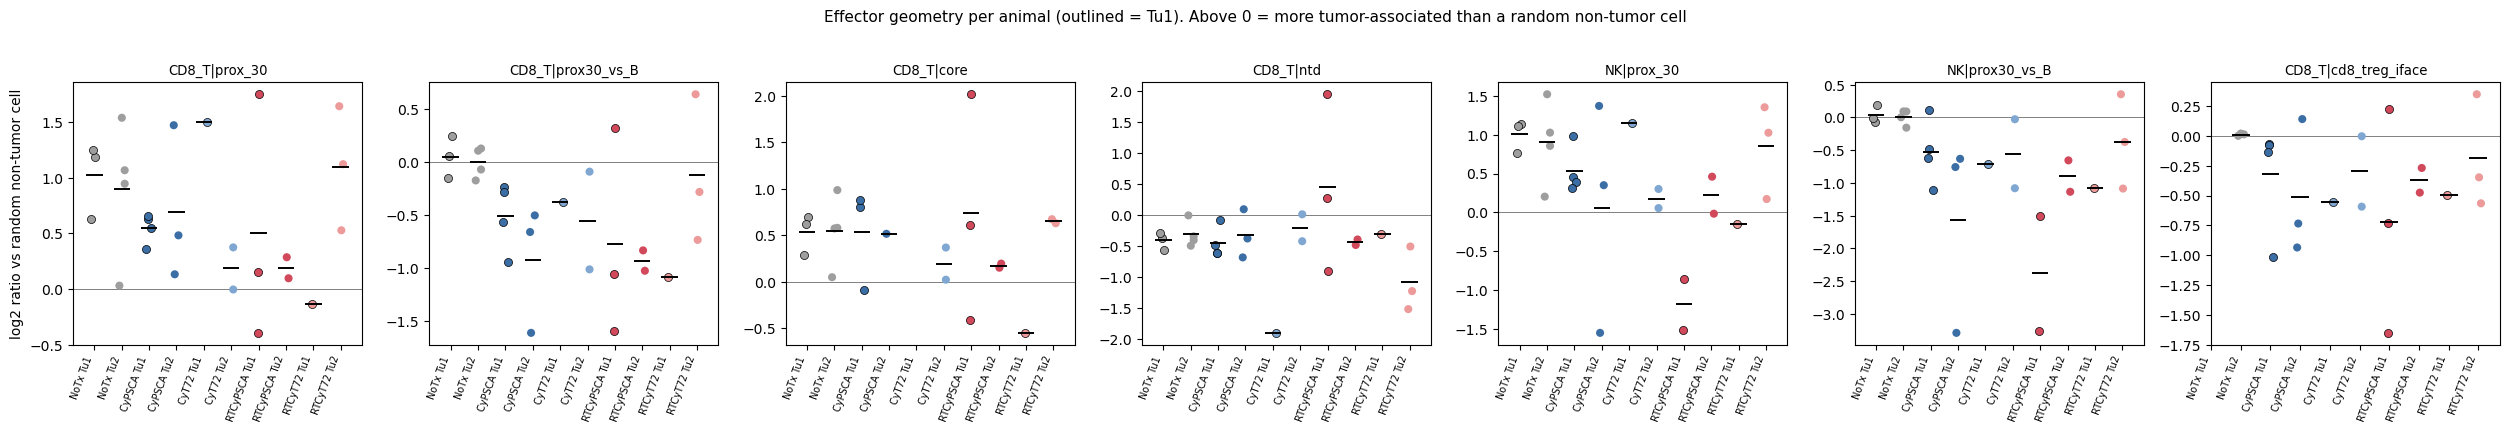

In [10]:
# (1) headline metrics, every animal, by arm x site
GR = [(a, s) for a in ARM_ORDER for s in (1, 2)]
fig, axes = plt.subplots(1, len(HEADLINE), figsize=(3.6*len(HEADLINE), 4.2))
for ax, col in zip(axes, HEADLINE):
    for i, (a, s) in enumerate(GR):
        v = W.loc[AM.index[(AM.arm == a) & (AM.site == s)], col].dropna() if col in W else []
        ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v,
                   color=COL[a], s=34, edgecolor="k" if s == 1 else "none", lw=.5, zorder=3)
        if len(v): ax.hlines(np.mean(v), i - .3, i + .3, color="k", lw=1.4, zorder=4)
    ax.axhline(0, color="0.5", lw=.7)
    ax.set_xticks(range(len(GR))); ax.set_xticklabels([f"{a} Tu{s}" for a, s in GR], rotation=70,
                                                      ha="right", fontsize=7)
    ax.set_title(col, fontsize=9.5)
axes[0].set_ylabel("log2 ratio vs random non-tumor cell")
fig.suptitle("Effector geometry per animal (outlined = Tu1). Above 0 = more tumor-associated than "
             "a random non-tumor cell", y=1.02, fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"04_infiltration_headline.png", dpi=220, bbox_inches="tight")
plt.show()

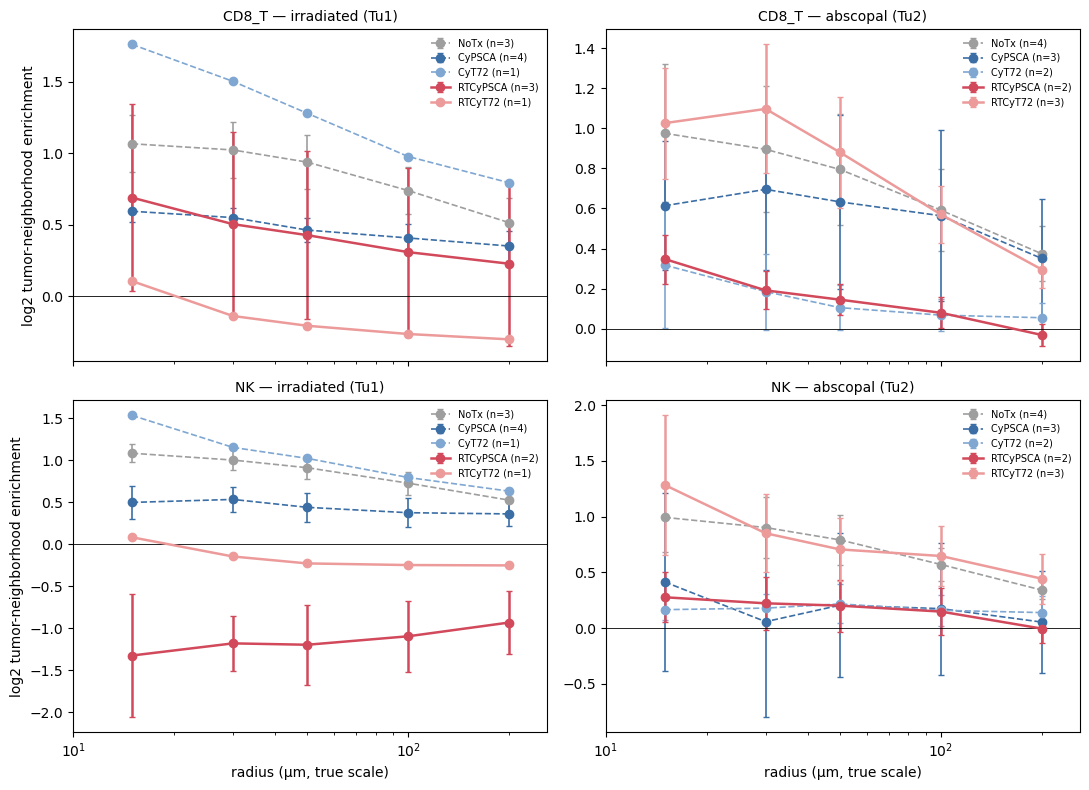

In [11]:
# (2) proximity enrichment vs radius — the range view
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax_row, e in zip(axes, ["CD8_T", "NK"]):
    for ax, s in zip(ax_row, (1, 2)):
        for a in ARM_ORDER:
            ids = AM.index[(AM.arm == a) & (AM.site == s)]
            cols_ = [f"{e}|prox_{r}" for r in RADII if f"{e}|prox_{r}" in W]
            Y = W.loc[ids, cols_].dropna()
            if Y.empty: continue
            ax.errorbar(RADII[:len(cols_)], Y.mean(), yerr=Y.sem() if len(Y) > 1 else None,
                        marker="o", color=COL[a], lw=1.8 if a.startswith("RT") else 1.2,
                        ls="-" if a.startswith("RT") else "--", capsize=2, label=f"{a} (n={len(Y)})")
        ax.axhline(0, color="k", lw=.6); ax.set_xscale("log"); ax.set_xlim(10, 260)
        ax.set_title(f"{e} — {SITE[s]} (Tu{s})", fontsize=10); ax.legend(fontsize=7, frameon=False)
for ax in axes[-1]: ax.set_xlabel("radius (µm, true scale)")
for ax in axes[:, 0]: ax.set_ylabel("log2 tumor-neighborhood enrichment")
fig.tight_layout(); fig.savefig(FIG/"04_proximity_vs_radius.png", dpi=220, bbox_inches="tight")
plt.show()

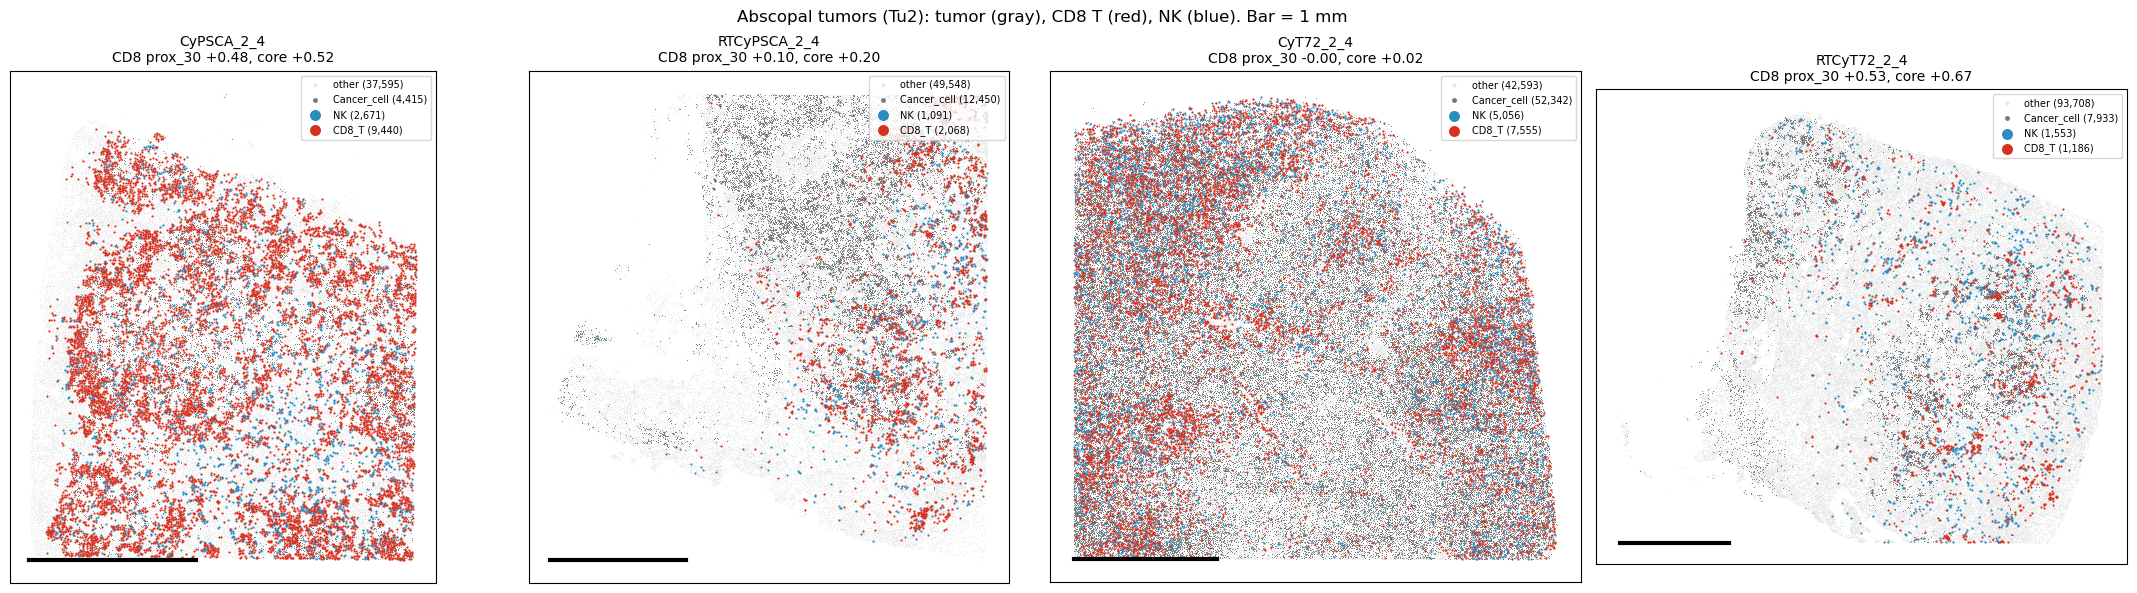

In [12]:
# (3) what it looks like: the abscopal tissue with most CD8 cells, per treated arm
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
for ax, a in zip(axes, ["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"]):
    c = M[(M.arm == a) & (M.site == 2) & (M.effector == "CD8_T") & M.usable]
    if c.empty: ax.axis("off"); continue
    t = c.sort_values("n_eff").tissue.iloc[-1]
    idx = np.where(so.tissue.values == t)[0]
    lab = so["c2l_consolidated"].values[idx]; xy = XY[idx]
    for ct_, colr, sz in [("other", "#e6e6e6", .3), (TUMOR, "#7a7a7a", .5),
                          ("NK", "#2b8cbe", 2.5), ("CD8_T", "#d7301f", 2.5)]:
        m = ~np.isin(lab, [TUMOR, "NK", "CD8_T"]) if ct_ == "other" else lab == ct_
        ax.scatter(xy[m, 0], xy[m, 1], s=sz, c=colr, lw=0, rasterized=True, label=f"{ct_} ({m.sum():,})")
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    r = c.set_index("tissue").loc[t]
    ax.set_title(f"{t}\nCD8 prox_30 {r.prox_30:+.2f}, core {r.core:+.2f}", fontsize=10)
    ax.plot([xy[:, 0].min(), xy[:, 0].min() + 1000], [xy[:, 1].max()] * 2, "k-", lw=3)
    ax.legend(markerscale=5, fontsize=7, loc="upper right")
fig.suptitle("Abscopal tumors (Tu2): tumor (gray), CD8 T (red), NK (blue). Bar = 1 mm", fontsize=12)
fig.tight_layout(); fig.savefig(FIG/"04_abscopal_maps.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Summary

In [13]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print(f"\n[scale] µm = px x {MICRONS_PER_PIXEL}; cell spacing {nn.median_nn_um.min():.1f}-"
      f"{nn.median_nn_um.max():.1f} µm across tissues -> distances are physical")
print(f"[units] {W.shape[0]} animals from {len(tis)} tissues; merged sections: "
      f"{sorted(merged.index)}")
uu = M[M.usable & (M.effector == "CD8_T")]
print(f"[usable for CD8] {len(uu)}/{len(tis)} tissues; excluded: "
      f"{sorted(set(tis.index) - set(uu.tissue))}")
print("[what the spatial design can estimate for CD8, animals usable (RT v non-RT)]")
for bg, rt, ct in CART_PAIRS:
    for s in (1, 2):
        na = W["CD8_T|prox_30"].reindex(AM.index[(AM.arm == rt) & (AM.site == s)]).notna().sum()
        nb = W["CD8_T|prox_30"].reindex(AM.index[(AM.arm == ct) & (AM.site == s)]).notna().sum()
        print(f"    {bg:<6s} {SITE[s]:<10s} {na}v{nb}  -> "
              f"{'estimable' if min(na, nb) >= 2 else 'NOT ESTIMABLE'}")

print("\n[yardsticks, headline metrics — median |effect| (log2) and share p<0.05]")
for k, t in list(BEN.items()) + [("RT", RTP)]:
    h = t[t.col.isin(HEADLINE)]
    eff = pd.concat([h[c] for c in h.columns if c.startswith("d_")]).abs()
    pc = pd.concat([h[c] for c in h.columns if c.startswith("p_") and c not in ("p_main", "p_inter")])
    print(f"    {k:<14s} median |delta| {eff.median():.2f}   per-background p<0.05 in "
          f"{(pc < 0.05).mean():5.1%}   (n tests {pc.notna().sum()})")

print("\n[RT effect on the headline metrics]")
for _, r in RTP[RTP.col.isin(HEADLINE)].iterrows():
    tag = ("SIGN-AGREE" if r.get("sign_agree") is True else
           "opposite" if r.get("sign_agree") is False else "one background only")
    print(f"    {r.stratum:<10s} {r.col:<22s} PSCA {r.d_PSCA:+.2f} ({r.n_PSCA})  TAG72 "
          f"{r.d_TAG72:+.2f} ({r.n_TAG72})  {tag:<20s} p_main={r.get('p_main', np.nan):.3f}  "
          f"p_inter={r.get('p_inter', np.nan):.3f}")

lead = RTP[(RTP.sign_agree == True) & (RTP.p_main < 0.10)]
print(f"\n[RT main-effect leads, any effector/metric: sign-agree and p_main<0.10] -> {len(lead)}")
for _, r in lead.sort_values("p_main").iterrows():
    print(f"    {r.stratum:<10s} {r.col:<24s} PSCA {r.d_PSCA:+.2f}  TAG72 {r.d_TAG72:+.2f}  "
          f"p_main={r.p_main:.3f}")
il = RTP[RTP.p_inter < 0.10]
print(f"[RT x CAR interaction leads, p_inter<0.10] -> {len(il)}")
for _, r in il.sort_values("p_inter").iterrows():
    print(f"    {r.stratum:<10s} {r.col:<24s} PSCA {r.d_PSCA:+.2f}  TAG72 {r.d_TAG72:+.2f}  "
          f"p_inter={r.p_inter:.3f}")
print(f"[site x RT (does RT change the Tu1-vs-Tu2 gap?)] sign-agree & p_main<0.10: "
      f"{DIDT[(DIDT.sign_agree == True) & (DIDT.p_main < 0.10)].col.tolist()}")
if len(ROB):
    print("\n[robustness of headline movers]")
    print(ROB[["col", "stratum", "main", "loo_flips"] +
              [c for c in ROB.columns if c.startswith("main_core") or c.startswith("strict")]]
          .round(2).to_string(index=False))
print(f"\n[files] {OUT}: infiltration_metrics_per_tissue.csv, infiltration_rt_contrasts.csv, "
      f"infiltration_site_x_rt.csv,\n        infiltration_robustness.csv, infiltration_<yardstick>.csv")
print(f"[figures] {FIG}: 04_infiltration_headline.png, 04_proximity_vs_radius.png, 04_abscopal_maps.png")
print("=" * 100)

SUMMARY — report these back

[scale] µm = px x 0.34; cell spacing 6.6-9.8 µm across tissues -> distances are physical
[units] 30 animals from 32 tissues; merged sections: ['RTCyPSCA_1_2', 'RTCyPSCA_1_5']
[usable for CD8] 27/32 tissues; excluded: ['CyPSCA_2_3', 'CyT72_1_4', 'NoTx_1_1', 'RTCyT72_1_1', 'RTCyT72_1_4']
[what the spatial design can estimate for CD8, animals usable (RT v non-RT)]
    PSCA   irradiated 3v4  -> estimable
    PSCA   abscopal   2v3  -> estimable
    TAG72  irradiated 1v1  -> NOT ESTIMABLE
    TAG72  abscopal   3v2  -> estimable

[yardsticks, headline metrics — median |effect| (log2) and share p<0.05]
    Tx vs NoTx     median |delta| 0.52   per-background p<0.05 in  7.1%   (n tests 19)
    CAR axis       median |delta| 0.51   per-background p<0.05 in  0.0%   (n tests 13)
    site, no RT    median |delta| 0.30   per-background p<0.05 in  0.0%   (n tests 6)
    site, with RT  median |delta| 0.57   per-background p<0.05 in  0.0%   (n tests 7)
    RT             medi